In [12]:
import pandas as pd

df = pd.read_csv("diabetes.csv")

print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}\n")

count_labels = df['Outcome'].value_counts()
print(count_labels.to_string(index=True))

print(f"\n{df.head().to_string(index=False)}")

Quantidade de linhas: 768
Quantidade de colunas: 9

Outcome
0    500
1    268

 Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  BMI  DiabetesPedigreeFunction  Age  Outcome
           6      148             72             35        0 33.6                     0.627   50        1
           1       85             66             29        0 26.6                     0.351   31        0
           8      183             64              0        0 23.3                     0.672   32        1
           1       89             66             23       94 28.1                     0.167   21        0
           0      137             40             35      168 43.1                     2.288   33        1


In [13]:
df = df.drop(columns=['Outcome'])
print(df.head().to_string(index=False))

 Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  BMI  DiabetesPedigreeFunction  Age
           6      148             72             35        0 33.6                     0.627   50
           1       85             66             29        0 26.6                     0.351   31
           8      183             64              0        0 23.3                     0.672   32
           1       89             66             23       94 28.1                     0.167   21
           0      137             40             35      168 43.1                     2.288   33


In [14]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
df_scaled = scaler.fit_transform(df)

df_scaled = pd.DataFrame(df_scaled, columns=df.columns)

print(df_scaled.head().to_string(index=False))

 Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin      BMI  DiabetesPedigreeFunction      Age
    0.352941 0.743719       0.590164       0.353535 0.000000 0.500745                  0.234415 0.483333
    0.058824 0.427136       0.540984       0.292929 0.000000 0.396423                  0.116567 0.166667
    0.470588 0.919598       0.524590       0.000000 0.000000 0.347243                  0.253629 0.183333
    0.058824 0.447236       0.540984       0.232323 0.111111 0.418778                  0.038002 0.000000
    0.000000 0.688442       0.327869       0.353535 0.198582 0.642325                  0.943638 0.200000


In [15]:
import numpy as np
from scipy.spatial.distance import pdist, squareform

def dunn_index(X, labels):
    unique_clusters = np.unique(labels[labels != -1])

    if len(unique_clusters) < 2:
        return np.nan

    intra_cluster_distances = [
        max(pdist(X[labels == c])) if X[labels == c].shape[0] > 1 else 0
        for c in unique_clusters
    ]

    inter_cluster_distances = np.min(squareform(pdist(X))[labels[:, None] != labels])

    if max(intra_cluster_distances) == 0 or np.isnan(inter_cluster_distances):
        return np.nan

    return inter_cluster_distances / max(intra_cluster_distances)

# K-MEANS

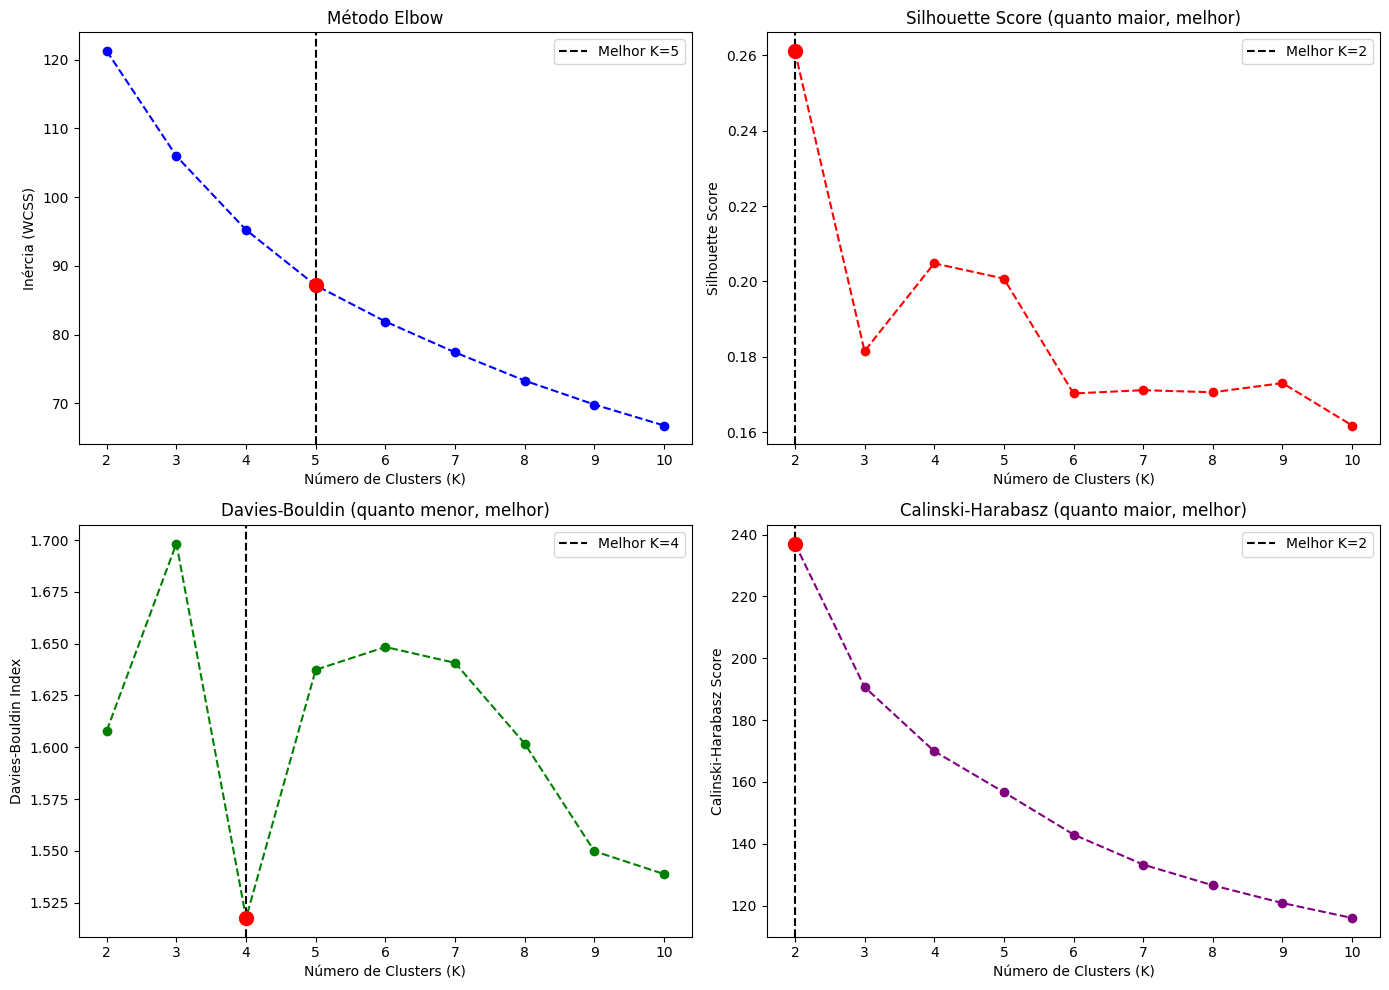

RESULTADOS - MELHOR K PARA CADA MÉTRICA
Melhor K pelo Método Elbow (maior cotovelo): 5
Melhor K pelo Silhouette Score (maior valor): 2
Melhor K pelo Davies-Bouldin (menor valor): 4
Melhor K pelo Calinski-Harabasz (maior valor): 2

TABELA COMPLETA PARA TODOS OS K:
----------------------------------------------------------------------
K     Inércia      Silhouette   Davies-Bouldin  Calinski-Harabasz
----------------------------------------------------------------------
2     121.26       0.2611       1.6081          237.11         
3     105.96       0.1815       1.6983          190.71         
4     95.24        0.2048       1.5176          169.95         
5     87.18        0.2008       1.6374          156.69         
6     81.92        0.1703       1.6484          143.00         
7     77.43        0.1711       1.6407          133.27         
8     73.32        0.1706       1.6017          126.56         
9     69.84        0.1730       1.5499          120.83         
10    66.80     

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.preprocessing import MinMaxScaler

num_clusters = range(2, 11)

wcss = []
silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores = []

for k in num_clusters:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_scaled)

    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, labels))
    davies_bouldin_scores.append(davies_bouldin_score(df_scaled, labels))
    calinski_harabasz_scores.append(calinski_harabasz_score(df_scaled, labels))

def find_elbow_point(wcss, k_values):
    wcss_array = np.array(wcss)
    k_array = np.array(k_values)

    wcss_norm = (wcss_array - min(wcss_array)) / (max(wcss_array) - min(wcss_array))
    k_norm = (k_array - min(k_array)) / (max(k_array) - min(k_array))

    x1, y1 = k_norm[0], wcss_norm[0]
    x2, y2 = k_norm[-1], wcss_norm[-1]

    distances = []
    for i, (x, y) in enumerate(zip(k_norm, wcss_norm)):
        dist = abs((y2-y1)*x - (x2-x1)*y + x2*y1 - y2*x1) / np.sqrt((y2-y1)**2 + (x2-x1)**2)
        distances.append(dist)

    return k_values[np.argmax(distances)]

best_k_elbow = find_elbow_point(wcss, list(num_clusters))
best_k_silhouette = num_clusters[np.argmax(silhouette_scores)]
best_k_davies = num_clusters[np.argmin(davies_bouldin_scores)]
best_k_calinski = num_clusters[np.argmax(calinski_harabasz_scores)]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(num_clusters, wcss, marker='o', linestyle='--', color='blue')
axes[0, 0].axvline(x=best_k_elbow, color='black', linestyle='--', label=f'Melhor K={best_k_elbow}')
axes[0, 0].scatter(best_k_elbow, wcss[list(num_clusters).index(best_k_elbow)], color='red', s=100, zorder=5)
axes[0, 0].set_xlabel('Número de Clusters (K)')
axes[0, 0].set_ylabel('Inércia (WCSS)')
axes[0, 0].set_title('Método Elbow')
axes[0, 0].legend()

axes[0, 1].plot(num_clusters, silhouette_scores, marker='o', linestyle='--', color='red')
axes[0, 1].axvline(x=best_k_silhouette, color='black', linestyle='--', label=f'Melhor K={best_k_silhouette}')
axes[0, 1].scatter(best_k_silhouette, silhouette_scores[list(num_clusters).index(best_k_silhouette)], color='red', s=100, zorder=5)
axes[0, 1].set_xlabel('Número de Clusters (K)')
axes[0, 1].set_ylabel('Silhouette Score')
axes[0, 1].set_title('Silhouette Score (quanto maior, melhor)')
axes[0, 1].legend()

axes[1, 0].plot(num_clusters, davies_bouldin_scores, marker='o', linestyle='--', color='green')
axes[1, 0].axvline(x=best_k_davies, color='black', linestyle='--', label=f'Melhor K={best_k_davies}')
axes[1, 0].scatter(best_k_davies, davies_bouldin_scores[list(num_clusters).index(best_k_davies)], color='red', s=100, zorder=5)
axes[1, 0].set_xlabel('Número de Clusters (K)')
axes[1, 0].set_ylabel('Davies-Bouldin Index')
axes[1, 0].set_title('Davies-Bouldin (quanto menor, melhor)')
axes[1, 0].legend()

axes[1, 1].plot(num_clusters, calinski_harabasz_scores, marker='o', linestyle='--', color='purple')
axes[1, 1].axvline(x=best_k_calinski, color='black', linestyle='--', label=f'Melhor K={best_k_calinski}')
axes[1, 1].scatter(best_k_calinski, calinski_harabasz_scores[list(num_clusters).index(best_k_calinski)], color='red', s=100, zorder=5)
axes[1, 1].set_xlabel('Número de Clusters (K)')
axes[1, 1].set_ylabel('Calinski-Harabasz Score')
axes[1, 1].set_title('Calinski-Harabasz (quanto maior, melhor)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

print("="*50)
print("RESULTADOS - MELHOR K PARA CADA MÉTRICA")
print("="*50)
print(f"Melhor K pelo Método Elbow (maior cotovelo): {best_k_elbow}")
print(f"Melhor K pelo Silhouette Score (maior valor): {best_k_silhouette}")
print(f"Melhor K pelo Davies-Bouldin (menor valor): {best_k_davies}")
print(f"Melhor K pelo Calinski-Harabasz (maior valor): {best_k_calinski}")
print("="*50)

print("\nTABELA COMPLETA PARA TODOS OS K:")
print("-"*70)
print(f"{'K':<5} {'Inércia':<12} {'Silhouette':<12} {'Davies-Bouldin':<15} {'Calinski-Harabasz':<15}")
print("-"*70)
for i, k in enumerate(num_clusters):
    print(f"{k:<5} {wcss[i]:<12.2f} {silhouette_scores[i]:<12.4f} {davies_bouldin_scores[i]:<15.4f} {calinski_harabasz_scores[i]:<15.2f}")
print("-"*70)

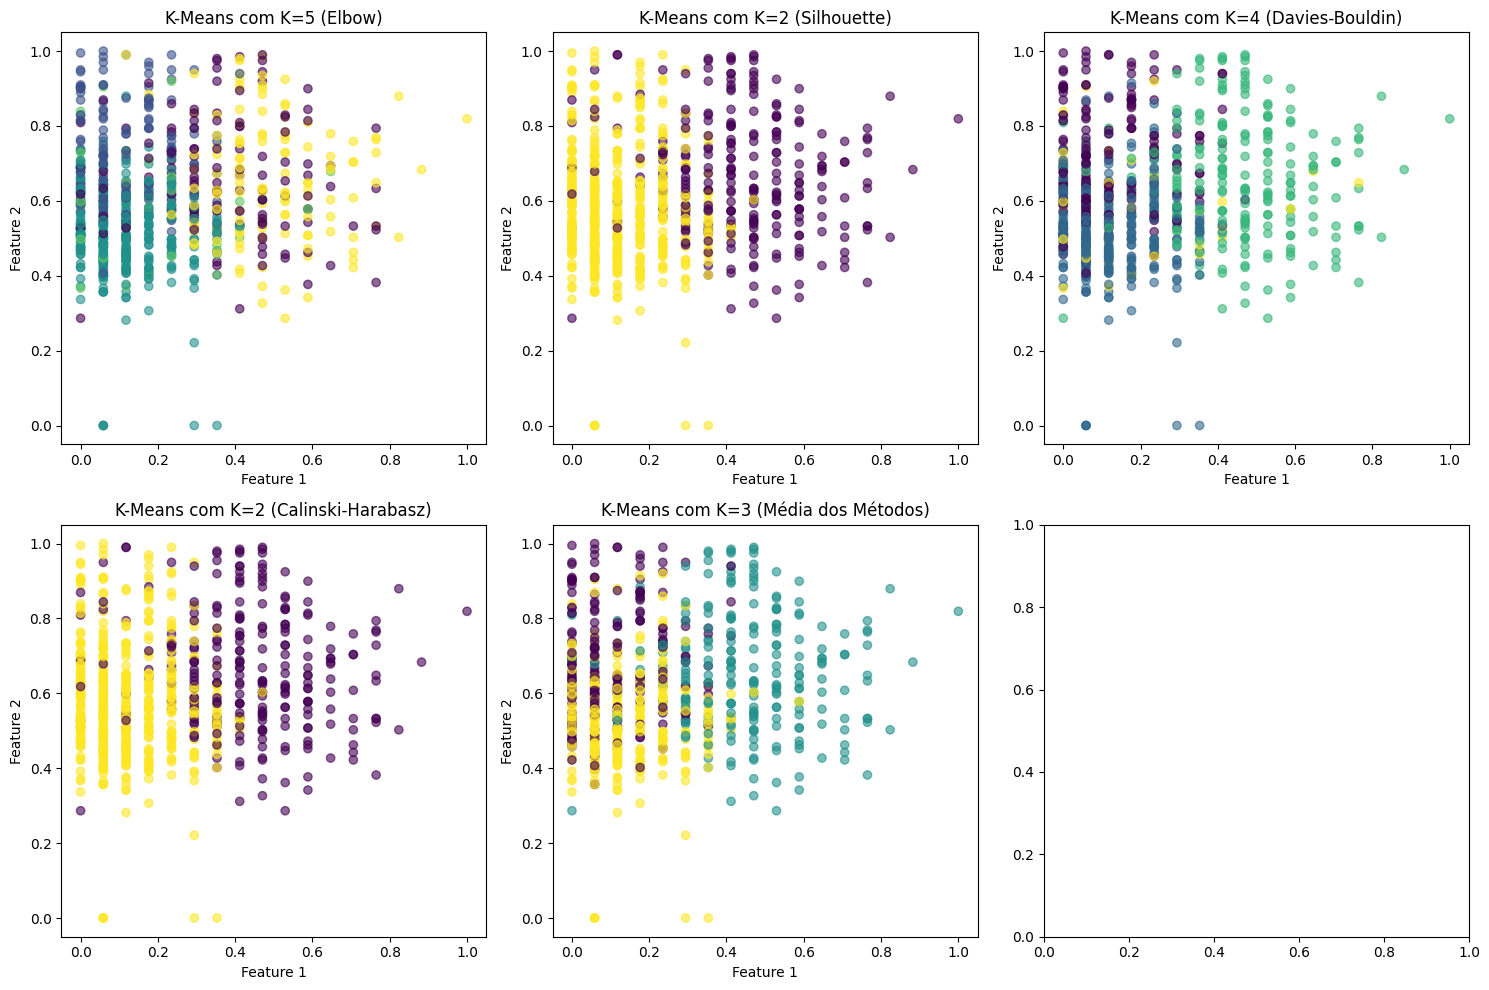

In [17]:
best_k_values = [best_k_elbow, best_k_silhouette, best_k_davies, best_k_calinski]
best_k_mean = int(np.round(np.mean(best_k_values)))
best_k_values_with_mean = best_k_values + [best_k_mean]
titles = ["Elbow", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "Média dos Métodos"]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, k in enumerate(best_k_values_with_mean):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    df["Cluster"] = kmeans.fit_predict(df_scaled)

    axes[i].scatter(df_scaled.iloc[:, 0], df_scaled.iloc[:, 1], c=df["Cluster"], cmap="viridis", alpha=0.6)
    axes[i].set_xlabel("Feature 1")
    axes[i].set_ylabel("Feature 2")
    axes[i].set_title(f"K-Means com K={k} ({titles[i]})")

plt.tight_layout()
plt.show()

In [18]:
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.stats import entropy
import numpy as np
from tabulate import tabulate
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import pairwise_distances

def dunn_index(X, labels):
    unique_labels = np.unique(labels)
    n_clusters = len(unique_labels)

    intra_dists = []
    inter_dists = []

    for i in range(n_clusters):
        cluster_i = X[labels == unique_labels[i]]
        if len(cluster_i) > 1:
            intra_dists.append(np.max(pairwise_distances(cluster_i)))
        else:
            intra_dists.append(0)

    for i in range(n_clusters):
        for j in range(i+1, n_clusters):
            cluster_i = X[labels == unique_labels[i]]
            cluster_j = X[labels == unique_labels[j]]
            inter_dists.append(np.min(pairwise_distances(cluster_i, cluster_j)))

    if max(intra_dists) == 0:
        return 0

    return min(inter_dists) / max(intra_dists)

unique_k_values = sorted(set(best_k_values))
metrics_results = []

for k in unique_k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_scaled)

    silhouette = silhouette_score(df_scaled, labels)
    davies_bouldin = davies_bouldin_score(df_scaled, labels)
    cluster_entropy = entropy(np.bincount(labels))
    dunn = dunn_index(df_scaled, labels)

    metrics_results.append([k, silhouette, dunn, davies_bouldin, cluster_entropy])

df_metrics = pd.DataFrame(metrics_results, columns=["K", "Silhouette Score", "Dunn Index", "Davies-Bouldin Index", "Entropia"])

print(tabulate(df_metrics, headers='keys', tablefmt='grid', showindex=False))
print("\nMétricas de Avaliação:")
print("- Silhouette Score: Quanto maior, melhor")
print("- Dunn Index: Quanto maior, melhor")
print("- Davies-Bouldin Index: Quanto menor, melhor")
print("- Entropia: Quanto menor, melhor")

+-----+--------------------+--------------+------------------------+------------+
|   K |   Silhouette Score |   Dunn Index |   Davies-Bouldin Index |   Entropia |
+=====+====================+==============+========================+============+
|   2 |           0.261146 |    0.0719208 |                1.60809 |   0.633772 |
+-----+--------------------+--------------+------------------------+------------+
|   4 |           0.204806 |    0.0561183 |                1.51759 |   1.20572  |
+-----+--------------------+--------------+------------------------+------------+
|   5 |           0.200757 |    0.0449214 |                1.63739 |   1.43989  |
+-----+--------------------+--------------+------------------------+------------+

Métricas de Avaliação:
- Silhouette Score: Quanto maior, melhor
- Dunn Index: Quanto maior, melhor
- Davies-Bouldin Index: Quanto menor, melhor
- Entropia: Quanto menor, melhor


# DBSCAN

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from tabulate import tabulate
from scipy.stats import entropy

eps_values = [0.3, 0.5, 0.7]
min_samples_values = [3, 5, 10]

results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(df_scaled)

        num_noise_points = np.sum(labels == -1)
        unique_clusters = set(labels) - {-1}
        num_clusters = len(unique_clusters)
        avg_cluster_size = np.mean([np.sum(labels == cluster) for cluster in unique_clusters]) if unique_clusters else "N/A"

        if num_clusters > 1:
            silhouette = silhouette_score(df_scaled, labels)
            davies_bouldin = davies_bouldin_score(df_scaled, labels)
            cluster_sizes = [np.sum(labels == cluster) for cluster in unique_clusters]
            entropia = entropy(cluster_sizes)
            dunn = dunn_index(df_scaled, labels)
        else:
            silhouette = "N/A"
            davies_bouldin = "N/A"
            entropia = "N/A"
            dunn = "N/A"

        results.append([eps, min_samples, num_clusters, silhouette, dunn, davies_bouldin, num_noise_points, avg_cluster_size, entropia])

df_results = pd.DataFrame(results, columns=[
    "Eps", "Min Samples", "Num Clusters", "Silhouette Score", "Dunn Index",
    "Davies-Bouldin Index", "Noise Points", "Avg Cluster Size", "Entropia"
])

for col in ["Silhouette Score", "Dunn Index", "Davies-Bouldin Index", "Avg Cluster Size", "Entropia"]:
    df_results[col] = df_results[col].apply(lambda x: f"{x:.3f}" if isinstance(x, float) else x)

df_results["Noise Points"] = df_results["Noise Points"].astype(int)

print(tabulate(df_results, headers='keys', tablefmt='grid', showindex=False))

print("\nMétricas de Avaliação:")
print("- Silhouette Score: Quanto maior, melhor (clusters bem separados).")
print("- Dunn Index: Quanto maior, melhor (clusters mais compactos e bem separados).")
print("- Davies-Bouldin Index: Quanto menor, melhor (clusters mais distintos).")
print("- Noise Points: Quanto menor, melhor (menos pontos classificados como ruído).")
print("- Avg Cluster Size: Média de quantidade de instâncias por cluster.")
print("- Num Clusters: Indica o número de agrupamentos distintos encontrados.")
print("- Entropia: Valor da dispersão dos pontos entre os grupos (Quanto menor, melhor).")

+-------+---------------+----------------+--------------------+--------------+------------------------+----------------+--------------------+------------+
|   Eps |   Min Samples |   Num Clusters | Silhouette Score   | Dunn Index   | Davies-Bouldin Index   |   Noise Points |   Avg Cluster Size | Entropia   |
+=======+===============+================+====================+==============+========================+================+====================+============+
|   0.3 |             3 |              3 | 0.181              | 0.187        | 2.019                  |             38 |            243.333 | 0.081      |
+-------+---------------+----------------+--------------------+--------------+------------------------+----------------+--------------------+------------+
|   0.3 |             5 |              3 | 0.256              | 0.158        | 2.380                  |             45 |            241     | 0.195      |
+-------+---------------+----------------+--------------------+-------

* Com eps = 0.3, o algoritmo encontra mais clusters distintos, mas há um número significativo de pontos classificados como ruído.
* Com eps = 0.5 e eps = 0.7, quase todos os pontos são agrupados em um único cluster grande, tornando impossível calcular métricas de separação como Silhouette Score e Davies-Bouldin Index.
* Valores maiores de eps tornam o agrupamento menos eficaz para identificar padrões reais nos dados.

# HIERÁRQUICO AGLOMERATIVO

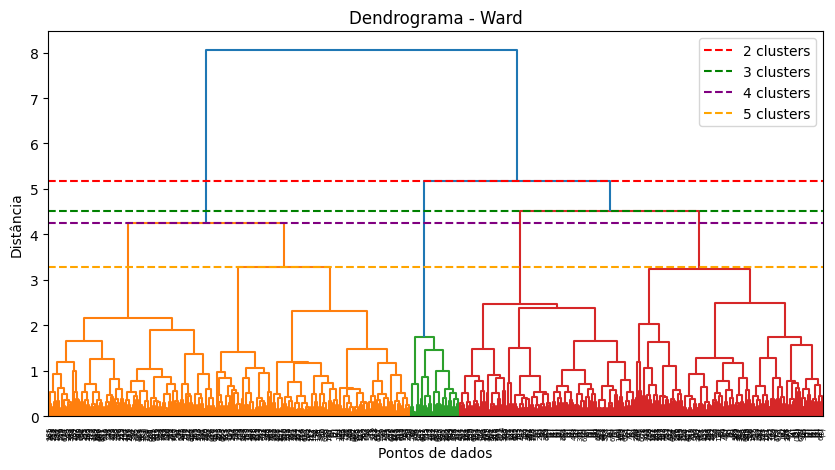

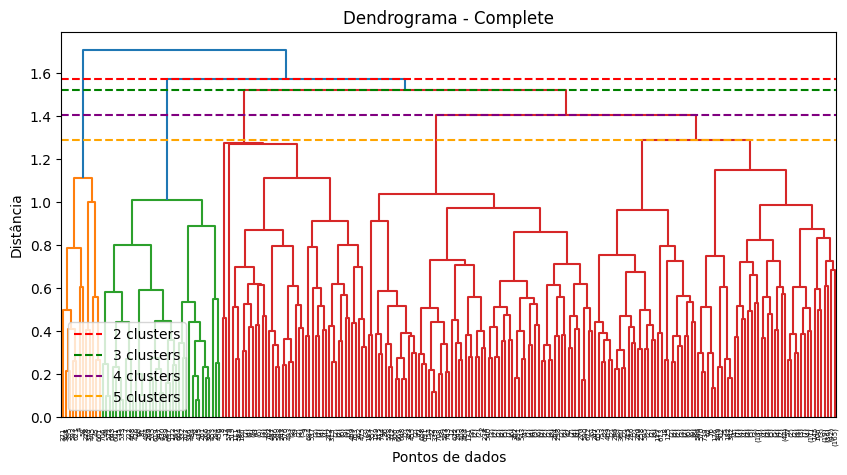

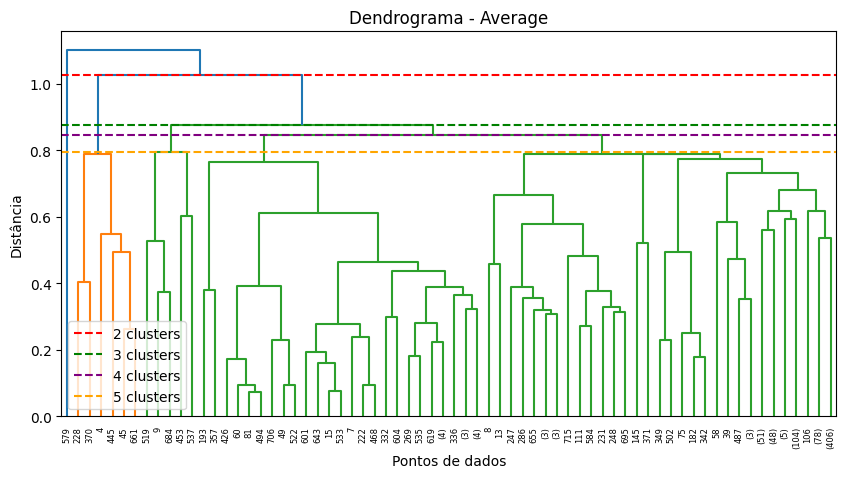

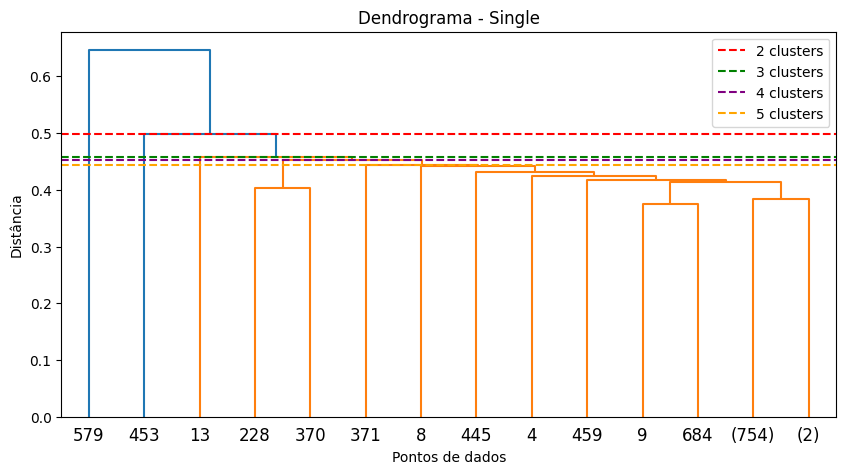

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from tabulate import tabulate

linkage_methods = ["ward", "complete", "average", "single"]
num_clusters_list = [2, 3, 4, 5]
colors = ["red", "green", "purple", "orange"]
cluster_data = []

for method in linkage_methods:
    linkage_matrix = linkage(df_scaled, method=method)
    distances = linkage_matrix[:, 2]
    color_thresholds = [np.sort(distances)[-num_clusters] for num_clusters in num_clusters_list]

    plt.figure(figsize=(10, 5))
    dendrogram(linkage_matrix, truncate_mode="level", p=10, color_threshold=max(color_thresholds))

    for threshold, color in zip(color_thresholds, colors):
        plt.axhline(y=threshold, color=color, linestyle="--", label=f"{num_clusters_list[color_thresholds.index(threshold)]} clusters")

    plt.legend()
    plt.title(f"Dendrograma - {method.capitalize()}")
    plt.xlabel("Pontos de dados")
    plt.ylabel("Distância")
    plt.show()

    for num_clusters, cutoff_distance in zip(num_clusters_list, color_thresholds):
        labels = fcluster(linkage_matrix, t=cutoff_distance, criterion="distance")
        unique_clusters, cluster_sizes = np.unique(labels, return_counts=True)

        for cluster, size in zip(unique_clusters, cluster_sizes):
            cluster_data.append([method.capitalize(), num_clusters, f"Cluster {cluster}", int(size)])

* Distâncias Grandes -> Clusters fundidos mais tarde pois estavam bem separados.
* Distâncias Pequenas -> Clusters se unem logo no início, indicando que os grupos eram muito próximos.

* **Single Linkage**: Agrupa os pontos mais próximos primeiro, criando clusters alongados e menos separados. É rápido, mas pode comprometer a definição dos grupos.
* **Complete Linkage**: Usa a maior distância entre pontos dos clusters, formando grupos mais bem separados e distintos, embora seja mais lento que o Single Linkage.
* **Average Linkage**: Calcula a média das distâncias entre os pontos, equilibrando separação e velocidade, criando clusters de maneira mais consistente.
* **Ward Linkage**: Minimiza a soma dos erros quadráticos dentro dos clusters, gerando fusões organizadas e bem distribuídas, mas exigindo mais tempo para consolidar os grupos.

In [21]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score, davies_bouldin_score
from collections import Counter
from scipy.cluster.hierarchy import linkage, fcluster
from tabulate import tabulate
from scipy.stats import entropy

def cluster_size_ratio(labels):
    counts = Counter(labels)
    return max(counts.values()) / min(counts.values()) if len(counts) > 1 else np.nan

def cluster_variance(labels):
    counts = list(Counter(labels).values())
    return np.std(counts) / np.mean(counts) if len(counts) > 1 else np.nan

cluster_data = []
metrics_data = []

for method in ["Ward", "Complete", "Average", "Single"]:
    linkage_matrix = linkage(df_scaled, method=method.lower())
    for num_clusters in [2, 3, 4, 5]:
        labels = fcluster(linkage_matrix, t=np.sort(linkage_matrix[:, 2])[-num_clusters], criterion="distance")

        silhouette = silhouette_score(df_scaled, labels) if num_clusters > 1 else np.nan
        dunn = dunn_index(df_scaled, labels) if num_clusters > 1 else np.nan
        davies_bouldin = davies_bouldin_score(df_scaled, labels) if num_clusters > 1 else np.nan
        cluster_counts = np.bincount(labels)
        entropia = entropy(cluster_counts[cluster_counts > 0])
        size_ratio = cluster_size_ratio(labels)
        variance = cluster_variance(labels)

        cluster_counts_str = " | ".join([f"Cluster {c}: {count} casos" for c, count in sorted(Counter(labels).items())])

        cluster_data.append([f"{method} ({num_clusters} clusters)", cluster_counts_str])
        metrics_data.append([f"{method} ({num_clusters} clusters)", silhouette, dunn, davies_bouldin, entropia, size_ratio, variance])

df_clusters = pd.DataFrame(cluster_data, columns=["Método (Nº de Clusters)", "Casos por Cluster"])
df_metrics = pd.DataFrame(metrics_data, columns=[
    "Método (Nº de Clusters)", "Silhueta", "Dunn", "Davies-Bouldin", "Entropia",
    "Proporção", "Variância"
])

print(tabulate(df_clusters, headers="keys", tablefmt="grid", showindex=False))
print("\n" + "="*130 + "\n")
print(tabulate(df_metrics, headers="keys", tablefmt="grid", showindex=False))

+---------------------------+-----------------------------------------------------------------------------------------------------------------+
| Método (Nº de Clusters)   | Casos por Cluster                                                                                               |
+===========================+=================================================================================================================+
| Ward (2 clusters)         | Cluster 1: 275 casos | Cluster 2: 493 casos                                                                     |
+---------------------------+-----------------------------------------------------------------------------------------------------------------+
| Ward (3 clusters)         | Cluster 1: 275 casos | Cluster 2: 35 casos | Cluster 3: 458 casos                                               |
+---------------------------+-----------------------------------------------------------------------------------------------------------

* Silhueta → Mede a separação e compactação dos clusters. Valores mais altos indicam que os pontos estão bem agrupados e separados dos outros grupos.
* Dunn → Avalia a distância entre clusters em relação à dispersão interna. Valores maiores indicam clusters bem separados e compactos.
* Davies-Bouldin → Mede a similaridade entre clusters. Quanto menor, melhor, pois significa que os clusters são distintos e bem formados.
* Entropia → Indica o nível de incerteza na classificação dos pontos. Valores menores sugerem clusters bem definidos.
* **Proporção (razão de tamanho)** → Valores menores indicam uma distribuição mais equilibrada.
* **Variância** → Mede a dispersão dos tamanhos dos clusters. Quanto menor, mais homogênea é a distribuição.


In [22]:
import pandas as pd
from IPython.core.display import display, HTML

data = {
    "Melhores Resultados": ["<b>K-Means (k=2)</b>", "DBSCAN (eps=0.3 | min_samples=3)", "Ward (2 clusters)"],
    "Silhouette Score": ["<b>0.261</b>",0.181,0.219],
    "Davies-Bouldin Index": ["<b>1.608</b>",2.019,1.776],
    "Entropia": [0.634,"<b>0.081</b>",0.941]
}

df_results = pd.DataFrame(data)

display(HTML(df_results.to_html(index=False, escape=False)))

Melhores Resultados,Silhouette Score,Davies-Bouldin Index,Entropia
K-Means (k=2),0.261,1.608,0.634
DBSCAN (eps=0.3 | min_samples=3),0.181,2.019,0.081
Ward (2 clusters),0.219,1.776,0.941
